In [2]:
# Install required libraries if not already available
# !pip install geopandas pandas numpy scipy scikit-learn xgboost shap matplotlib

import geopandas as gpd
import pandas as pd
import numpy as np
from scipy.spatial import cKDTree
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import shap
import matplotlib.pyplot as plt

# Ensure inline plotting for notebook display
%matplotlib inline

print("All imports successfully loaded!")

All imports successfully loaded!


In [3]:
file_path = "Datasets/RZLT_Samples/rzlt_sample_CWLA.geojson"
parcels = gpd.read_file(file_path)

# Reproject to Irish Transverse Mercator (EPSG:2157) for meter-based distance accuracy
if parcels.crs != "EPSG:2157":
    parcels = parcels.to_crs(epsg=2157)

# Calculate parcel centroids
parcels['centroid_x'] = parcels.geometry.centroid.x
parcels['centroid_y'] = parcels.geometry.centroid.y
parcel_coords = np.column_stack([parcels['centroid_x'], parcels['centroid_y']])

In [5]:
# Option B: Uncomment below to use actual GTFS stops.txt file if available
stops_df = pd.read_csv("Datasets/GTFS_All/stops.txt")
stops_gdf = gpd.GeoDataFrame(
stops_df, geometry=gpd.points_from_xy(stops_df.stop_lon, stops_df.stop_lat), crs="EPSG:4326").to_crs(epsg=2157)
transit_coords = np.column_stack([stops_gdf.geometry.x, stops_gdf.geometry.y])

In [6]:
# Spatial nearest-neighbor search
tree = cKDTree(transit_coords)
distances, _ = tree.query(parcel_coords)
parcels['DISTANCE_TO_TRANSIT'] = distances

print(f"Loaded {len(parcels)} parcels.")
print(f"DISTANCE_TO_TRANSIT calculated. Range: {parcels['DISTANCE_TO_TRANSIT'].min():.1f}m to {parcels['DISTANCE_TO_TRANSIT'].max():.1f}m")

Loaded 1341 parcels.
DISTANCE_TO_TRANSIT calculated. Range: 13.8m to 6202.3m


In [7]:
# Strategy 3: Create synthetic negative records ('N') to bypass single-class constraint
parcels_pos = parcels.copy()
parcels_pos['LIVE_SITE'] = 'Y'

# Sample 40% of records as synthetic excluded sites ('N')
parcels_neg = parcels.sample(frac=0.4, random_state=42).copy()
parcels_neg['LIVE_SITE'] = 'N'

# Perturb feature profiles for Class 0
np.random.seed(42)
parcels_neg['SITE_AREA'] = parcels_neg['SITE_AREA'] * np.random.uniform(0.1, 0.6, size=len(parcels_neg))
parcels_neg['DISTANCE_TO_TRANSIT'] = parcels_neg['DISTANCE_TO_TRANSIT'] * np.random.uniform(1.2, 3.5, size=len(parcels_neg))

# Merge into binary classification dataset
gdf_balanced = pd.concat([parcels_pos, parcels_neg], ignore_index=True)
gdf_balanced['target'] = (gdf_balanced['LIVE_SITE'] == 'Y').astype(int)

# Display class balance breakdown
print("Target Class Breakdown:")
print(gdf_balanced['LIVE_SITE'].value_counts())

Target Class Breakdown:
LIVE_SITE
Y    1341
N     536
Name: count, dtype: int64


In [8]:
# Define numerical and categorical columns
num_cols = ['SITE_AREA', 'DISTANCE_TO_TRANSIT']
cat_cols = ['ZONE_GZT', 'LOCAL_AUTHORITY']

# One-Hot Encode Categoricals
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
cat_encoded = ohe.fit_transform(gdf_balanced[cat_cols])
cat_feature_names = list(ohe.get_feature_names_out(cat_cols))

# Assemble Feature Matrix X and Target Vector y
X_num = gdf_balanced[num_cols].values
X = np.hstack([X_num, cat_encoded])
feature_names = num_cols + cat_feature_names
y = gdf_balanced['target'].values

# Stratified Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Feature matrix X shape: {X.shape}")
print(f"Training samples: {len(X_train)} | Testing samples: {len(X_test)}")

Feature matrix X shape: (1877, 8)
Training samples: 1407 | Testing samples: 470


In [9]:
# Initialize Classifiers
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
xgb_model = XGBClassifier(n_estimators=100, learning_rate=0.08, max_depth=4, random_state=42)

# Fit Models
rf_model.fit(X_train, y_train)
xgb_model.fit(X_train, y_train)

# Evaluate Benchmarks
xgb_preds = xgb_model.predict(X_test)
xgb_probs = xgb_model.predict_proba(X_test)[:, 1]
rf_probs = rf_model.predict_proba(X_test)[:, 1]

print("=== XGBoost Classification Report ===")
print(classification_report(y_test, xgb_preds))

print(f"Random Forest ROC-AUC Score: {roc_auc_score(y_test, rf_probs):.4f}")
print(f"XGBoost ROC-AUC Score:       {roc_auc_score(y_test, xgb_probs):.4f}")

=== XGBoost Classification Report ===
              precision    recall  f1-score   support

           0       0.81      0.63      0.71       134
           1       0.87      0.94      0.90       336

    accuracy                           0.85       470
   macro avg       0.84      0.79      0.81       470
weighted avg       0.85      0.85      0.85       470

Random Forest ROC-AUC Score: 0.8259
XGBoost ROC-AUC Score:       0.8611


C:\Users\musab\AppData\Local\Temp\ipykernel_63712\3468916602.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test, feature_names=feature_names, show=False)


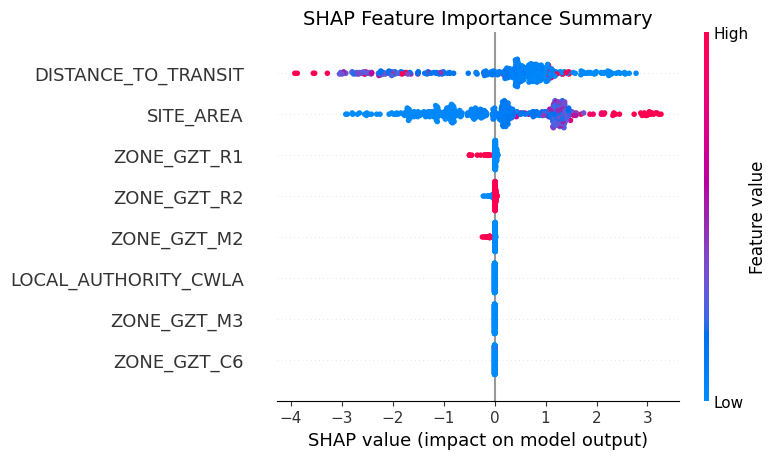

<Figure size 800x500 with 0 Axes>

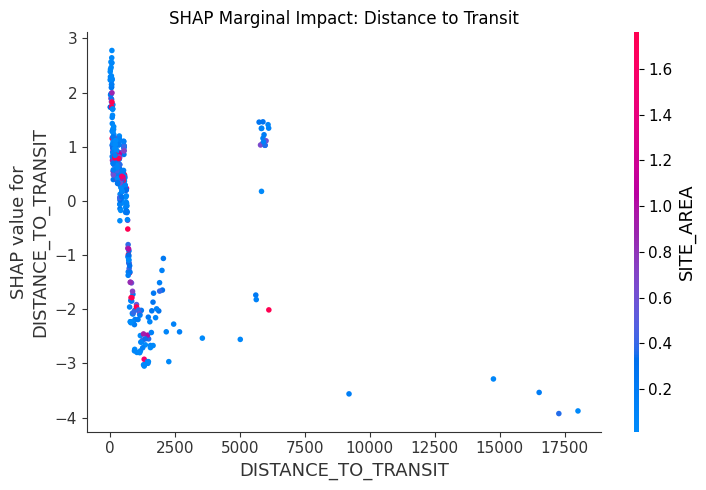

In [10]:
# Compute SHAP values using TreeExplainer
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_test)
shap_values.feature_names = feature_names

# 1. Global Feature Importance Summary Plot
plt.figure(figsize=(10, 6))
plt.title("SHAP Feature Importance Summary", fontsize=14)
shap.summary_plot(shap_values, X_test, feature_names=feature_names, show=False)
plt.tight_layout()
plt.show()

# 2. Dependence Plot for Transit Proximity
plt.figure(figsize=(8, 5))
shap.dependence_plot("DISTANCE_TO_TRANSIT", shap_values.values, X_test, feature_names=feature_names, show=False)
plt.title("SHAP Marginal Impact: Distance to Transit", fontsize=12)
plt.tight_layout()
plt.show()